# XDP NucSeq: NEBULA DEG XDP vs Control

Same logic, functions and parameters as `script/HD_Handsaker/DEG/Handsaker_DEG_VILLAGE_NEBULA.ipynb`, on the XDP NucSeq dataset (`TISSUE`) and with `condition` as the response.

For each group of cells (analysed separately), one model per gene:

```
counts ~ RESPONSE + COVARIATES [+ factors] + (1 | donor_id),   offset = total_counts
```

and the coefficient of `RESPONSE` is tested.
* Default: categorical `condition`, `log2FC` of `XDP` (`RESPONSE_TESTED`) vs `Control` (`RESPONSE_BASELINE`). Every donor has one condition, so the test is between donors.
* A numeric response (any numeric obs column) also works: `log2FC` per unit of it.

**Groups**: the cell types are the values of `CELLTYPE_COL`. With `MERGE_CELL_TYPES = False` every cell type is analysed on its own (cell types starting with `-` are removed); with `True` only the merged groups of `CELLTYPE_MERGE` are analysed (e.g. Matrix_D1 + Matrix_D2 → Matrix) and the other cell types are ignored. Only groups that have factors are kept (e.g. a BICAN PCA file of the same name).

**Factors** (`FACTOR_METHOD`), computed on reference cells (`FACTORS_FROM`: `"bican"` or `"healthy_samples"` = Control cells of this dataset) and transferred to every cell, so the XDP donors never shape them:
* `"pca"`: PCs (BICAN PCA from `PCA_on_BICAN.ipynb`, or fitted here); the model uses PC_1 … knee of the scree plot.
* `"cnmf"`: GEP usages on cNMF spectra trained outside this notebook (`CNMF_SPECTRA`).
* `"dv_score"`: dorsal–ventral position score from genes with a stable spatial gradient in BICAN health and XDP (as in `NucSeq_DEG_factors.ipynb`).
* `"none"`: baseline only.

`FACTOR_ASSOCIATION` then keeps all factors, only those associated with the response, or drops those.

**Models** per group: `baseline` (no factors) and one factor model. The baseline does not depend on the factors: it is fitted once per `RESPONSE` and reused by the other factor runs (`REUSE_BASELINE`).

In [86]:
%load_ext autoreload
%autoreload 2

import os
import sys
import warnings
import numpy as np
import pandas as pd
import scipy.sparse as sp
import scanpy as sc
import anndata as ad
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.formula.api as smf
from statsmodels.stats.multitest import multipletests
import h5py
from adjustText import adjust_text
import decoupler as dc

from utils import reference_pca
from utils import DEG          # ATTENTION: imports pertpy, which switches matplotlib to Agg -> must come before %matplotlib inline

# NEBULA runner of generalisable_DEG: fits gene chunks in parallel in R, returns NEBULA's table
sys.path.insert(0, "/home/gdallagl/myworkdir/data/_old/generalisable_DEG")
from functions import nebula as nebula_runner

%matplotlib inline

TISSUE = "Striatum"              # "Striatum", "DFC", "SN" (no BICAN PCs for DFC / SN: use FACTORS_FROM = "healthy_samples")
ADATA_PATH = {
    "Striatum": "/home/gdallagl/myworkdir/XDP/data/XDP/NucSec/adatas/Striatum/Striatum_combined_QC_mmc_ct-cured_zoned.h5ad",
    "DFC": "/home/gdallagl/myworkdir/XDP/data/XDP/NucSec/adatas/DFC/DFC_combined_QC_mmc_ct-cured.h5ad",
    "SN": "/home/gdallagl/myworkdir/XDP/data/XDP/NucSec/adatas/SN/SN_combined_QC_mmc_ct-cured.h5ad",
}[TISSUE]
DONOR_COL = "donor_id"
LIBRARY_SIZE_COL = "total_counts"

# ------------------------------------------------------------------------------------------ groups of cells
# column with the cell types
CELLTYPE_COL = "ct_for_deg"
# False: every cell type of CELLTYPE_COL is analysed on its own (cell types starting with "-" are removed)
# True:  only the merged groups of CELLTYPE_MERGE are analysed, all other cell types are ignored
# ATTNETION: a cell tyep cannpot be in mroe then one group, other wise dorn knwohee to put it --> MAKE MULTIPLE RUNS
MERGE_CELL_TYPES = False
CELLTYPE_MERGE = {               # merged group -> cell types pooled into it
    # "Matrix": ["Matrix_D1", "Matrix_D2"],
    # "Patch":  ["Patch_D1", "Patch_D2"],
    # "eMSN_D1D2": ["eMSN_D1D2"],

    "MSN": ["Matrix_D1", "Matrix_D2", "Patch_D1", "Patch_D2", "-Phase_D"]

}
# example, all MSNs as one group (BICAN file MSN.h5ad exists):
#   CELLTYPE_MERGE = {"MSN": ["Matrix_D1", "Matrix_D2", "Patch_D1", "Patch_D2"]}
# ATTENTION: only groups with factors are analysed: FACTORS_FROM = "bican" needs a BICAN file of the same name
# in BICAN_PCA_DIR (made by PCA_on_BICAN.ipynb), dv_score needs an entry in DV_GRADIENT_CT

# ------------------------------------------------------------------------------------------ tested variable
RESPONSE = "condition"           # any obs column; categorical (e.g. "condition") or numeric
RESPONSE_TYPE = "categorical"    # "numeric" or "categorical"
RESPONSE_BASELINE = "Control"    # categorical only: reference level
RESPONSE_TESTED = "XDP"          # categorical only: level tested against the baseline

# healthy cells (reference of FACTORS_FROM = "healthy_samples")
CONDITION_COL = "condition"
HEALTHY_LEVEL = "Control"

# ------------------------------------------------------------------------------------------ covariates
# column -> numeric / categorical; covariates constant in a group are dropped
COVARIATES = {"age_of_death": "numeric", "sex": "categorical", "pct_counts_mt": "numeric", "frac_intronic": "numeric",
              "cohort": "categorical", "msn_subtype": "categorical"}

# z-scored over the model cells of each group (only their own coefficients change, not the tested one)
STANDARDISE = ["age_of_death", "pct_counts_mt", "frac_intronic"]
STANDARDISE_FACTORS = True # eg PCs

# ------------------------------------------------------------------------------------------ cells and genes
MIN_CELLS_PER_DONOR = 10     # donors with fewer model cells in a group are removed from that group
MIN_DONORS = 4               # groups with fewer donors left in either level of a categorical response (numeric: in total) are skipped
MIN_COUNTS_PER_GENE = 50     # gene tested if >= this many counts AND detected in >= n_donors x MIN_CELLS_PER_DONOR cells

# genes forced to be tested
HANDSAKER_GENES_DIR = "/home/gdallagl/myworkdir/XDP/utils/handsaker_et_all"
FORCE_KEEP_PHASES = ["c_plus", "c_minus", "d"]   # Handsaker phase genes tested anyway, if detected in >= 1 cell

# ------------------------------------------------------------------------------------------ factors
FACTOR_METHOD = "pca"            # "none", "pca", "cnmf", "dv_score"
FACTORS_FROM = "healthy_samples"           # pca / cnmf reference: "bican" or "healthy_samples" (Control cells of this dataset)


# factors associated with the response (LMM factor ~ response + covariates + (1|donor))
FACTOR_ASSOCIATION = "all"       # "all": keep every factor | "only_associated": keep only them | "drop_associated": remove them
ASSOC_FDR = 0.05                 # associated = FDR below this ...
ASSOC_MIN_ABS_BETA = 0.1         # ... and |beta| >= this (factor SDs per unit of the response, or tested vs baseline)

# pca: BICAN files, or the parameters to fit it on the Control cells of this dataset
BICAN_PCA_DIR = "/home/gdallagl/myworkdir/XDP/data/BICAN/bican_spatial_zonated/pca_bican"   # from PCA_on_BICAN.ipynb
MIN_CELLS_PER_GENE_REF = 5       # healthy_samples: same PCA steps as the BICAN notebook
TARGET_SUM = 1e4
N_HVG = 3000
N_PCS = 50
SEED = 0
N_PCS_TO_TEST = 20               # PCs tested for association with the response (at least up to the knee)

# cnmf: spectra (*.spectra.k_K.dt_D.consensus.txt, GEPs x genes) trained outside this notebook on the reference counts:
#   bican:           {BICAN_PCA_DIR}/cnmf_input/<group>.h5ad (written by PCA_on_BICAN.ipynb)
#   healthy_samples: {OUT_DIR}/<group>/cnmf_input.h5ad (written here for a group without spectra; the notebook then stops)
CNMF_SPECTRA = {}                # group -> spectra file
CNMF_NORMALISE = True            # usages as fractions per cell; the last GEP is then dropped (the fractions sum to 1)

# dv_score: gradient genes from the BICAN spatial correlations, health and XDP
DV_CORR_DIR = "/home/gdallagl/myworkdir/XDP/data/BICAN/bican_spatial_zonated/genes_correlation"
DV_GRADIENT_CT = {"Matrix": "Matrix", "Patch": "Patch", "eMSN_D1D2": "eMSN"}   # group -> gradient columns used (rho_<ct>: Matrix, Patch, eMSN)
DV_MIN_ABS_RHO = 0.2             # |rho| at least this in EACH condition, same sign
DV_PADJ = 0.05
DV_MIN_PCT_EXPR = 0.20
DV_MIN_MEAN_EXPR = 0.10

# ------------------------------------------------------------------------------------------ NEBULA
NEBULA_METHOD = "LN"
N_FOLDS = 40                 # gene chunks
N_CORES = 40                 # chunks fitted in parallel
NEBULA_CPC = 0               # NEBULA's own gene filter, lowered so that the forced genes are kept (defaults 0.005 and 5)
NEBULA_MINCP = 1
FDR = 0.05

# ------------------------------------------------------------------------------------------ plots
N_LABELS = 10                # volcano: significant genes with the largest |log2FC| labelled
LOGFC_THR = 0.25             # volcano with gene sets: vertical lines
MAX_X = 3                    # volcano with gene sets: |log2FC| above this is drawn at the edge

OUT_DIR = f"/home/gdallagl/myworkdir/XDP/data/XDP/NucSec/DEG/{TISSUE}/nebula_v2/{RESPONSE}__{FACTOR_METHOD}_{FACTORS_FROM}"
os.makedirs(OUT_DIR, exist_ok=True)

# baseline (no factors) shared by all factor runs of the same RESPONSE: fitted once, then loaded,
# as long as cells, genes, design and NEBULA settings are the same (otherwise fitted again)
REUSE_BASELINE = True
BASELINE_DIR = f"{os.path.dirname(OUT_DIR)}/{RESPONSE}__baseline"

# name of the tested coefficient in NEBULA's output (R names a categorical level <column><level>, e.g. conditionXDP)
coef = RESPONSE if RESPONSE_TYPE == "numeric" else RESPONSE + RESPONSE_TESTED
OUT_DIR

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


'/home/gdallagl/myworkdir/XDP/data/XDP/NucSec/DEG/Striatum/nebula_v2/condition__pca_healthy_samples'

# Load the cells of the groups
Groups: every cell type of `CELLTYPE_COL`, or only the merged groups (`MERGE_CELL_TYPES`). Groups without factors are skipped.

All donors and statuses are loaded: the Control cells are needed for `FACTORS_FROM = "healthy_samples"`.

The Striatum file is large (31 GB, 230k cells, 950 million non-zeros in each layer, and `backed="r"` still loads the layers in memory): only obs / var are read, then the raw counts of the cells of the groups.

In [87]:
with h5py.File(ADATA_PATH, "r") as f:
    obs = ad.io.read_elem(f["obs"])
    var = ad.io.read_elem(f["var"])
celltype = obs[CELLTYPE_COL].astype(str)

# group of each cell
if MERGE_CELL_TYPES:
    celltype_to_group = {ct: group for group, cts in CELLTYPE_MERGE.items() for ct in cts}
    cell_group = celltype.map(celltype_to_group)                # cell types not merged -> NaN (ignored)
else:
    # ATTENTION: cell types starting with "-" are bad-quality / removed labels (-Low_quality, -TAFA1)
    cell_group = celltype.where(~celltype.str.startswith("-"))

# only groups that have factors (e.g. a BICAN PCA file of the same name)
groups = sorted(cell_group.dropna().unique())
if FACTOR_METHOD == "pca" and FACTORS_FROM == "bican":
    skipped = [g for g in groups if not os.path.exists(f"{BICAN_PCA_DIR}/{g}.h5ad")]
elif FACTOR_METHOD == "cnmf" and FACTORS_FROM == "bican":
    skipped = [g for g in groups if not os.path.exists(f"{BICAN_PCA_DIR}/cnmf_input/{g}.h5ad")]
elif FACTOR_METHOD == "dv_score":
    skipped = [g for g in groups if g not in DV_GRADIENT_CT]
else:
    skipped = []
groups = [g for g in groups if g not in skipped]
print("groups analysed:", groups)
print("skipped, no factors for them:", skipped)

# raw counts of the cells of the groups only
rows = np.where(cell_group.isin(groups).values)[0]
with h5py.File(ADATA_PATH, "r") as f:
    counts = ad.io.sparse_dataset(f["layers/counts"])[rows]

# ATTENTION: raw counts in X; var_names are Ensembl IDs (NEBULA runs on them), gene names in var["gene_name"]
adata = ad.AnnData(X=sp.csr_matrix(counts).astype(np.int32), obs=obs.iloc[rows].copy(), var=var[["gene_symbol"]].copy())
adata.var["gene_name"] = adata.var["gene_symbol"].astype(str)
adata.obs["group"] = cell_group.iloc[rows].values
adata.obs[DONOR_COL] = adata.obs[DONOR_COL].astype(str)
del obs, var, counts
print(adata)

display(pd.crosstab(adata.obs[CELLTYPE_COL].astype(str), adata.obs["group"]))
pd.crosstab(adata.obs[CONDITION_COL].astype(str), adata.obs["group"], values=adata.obs[DONOR_COL], aggfunc="nunique")

groups analysed: ['Astrocyte', 'COP', 'Endothelial_BBB', 'Ependymal', 'Fibroblasts', 'Lymphocyte', 'Macrophages', 'Matrix_D1', 'Matrix_D2', 'Microglia', 'Monocytes', 'OPC', 'Oligodendrocyte', 'Patch_D1', 'Patch_D2', 'Pericytes', 'SmoothMuscleCells', 'eMSN_D1D2', 'eMSN_NUDAP', 'eMSN_StrioMat', 'non-MSN']
skipped, no factors for them: []
AnnData object with n_obs × n_vars = 215640 × 38601
    obs: 'background_fraction', 'cell_probability', 'cell_size', 'droplet_efficiency', 'barcode', 'bcl', 'rna_index', 'library', 'library__barcode', 'frac_mito', 'mol_info_nUMI', 'mol_info_nRead', 'frac_intronic', 'donor_id', 'vireo_prob_max', 'vireo_prob_doublet', 'vireo_n_vars', 'vireo_best_singlet', 'vireo_best_doublet', 'vireo_doublet_logLikRatio', 'dropsift_frac_contamination', 'dropsift_training_label_is_cell', 'dropsift_empty_gene_module_score', 'dropsift_is_cell', 'dropsift_is_cell_prob', 'cell_class', 'leiden_0.1', 'leiden_0.2', 'leiden_0.3', 'leiden_0.4', 'leiden_0.5', 'tissue', 'broad_origina

group,Astrocyte,COP,Endothelial_BBB,Ependymal,Fibroblasts,Lymphocyte,Macrophages,Matrix_D1,Matrix_D2,Microglia,...,OPC,Oligodendrocyte,Patch_D1,Patch_D2,Pericytes,SmoothMuscleCells,eMSN_D1D2,eMSN_NUDAP,eMSN_StrioMat,non-MSN
ct_for_deg,,,,,,,,,,,,,,,,,,,,,
Astrocyte,27715,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
COP,0,440,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
Endothelial_BBB,0,0,711,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
Ependymal,0,0,0,1451,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
Fibroblasts,0,0,0,0,230,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
Lymphocyte,0,0,0,0,0,415,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
Macrophages,0,0,0,0,0,0,761,0,0,0,...,0,0,0,0,0,0,0,0,0,0
Matrix_D1,0,0,0,0,0,0,0,11037,0,0,...,0,0,0,0,0,0,0,0,0,0
Matrix_D2,0,0,0,0,0,0,0,0,11745,0,...,0,0,0,0,0,0,0,0,0,0


group,Astrocyte,COP,Endothelial_BBB,Ependymal,Fibroblasts,Lymphocyte,Macrophages,Matrix_D1,Matrix_D2,Microglia,...,OPC,Oligodendrocyte,Patch_D1,Patch_D2,Pericytes,SmoothMuscleCells,eMSN_D1D2,eMSN_NUDAP,eMSN_StrioMat,non-MSN
condition,,,,,,,,,,,,,,,,,,,,,
Control,17.0,17.0,17.0,17.0,16.0,14.0,17.0,17.0,17.0,17.0,...,17.0,17.0,17.0,17.0,15.0,9.0,17.0,17.0,17.0,17.0
XDP,30.0,30.0,30.0,30.0,29.0,29.0,30.0,30.0,30.0,30.0,...,30.0,30.0,30.0,30.0,30.0,20.0,30.0,30.0,30.0,30.0
nan,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


# Prepare variables (XDP)
* `condition`, `sex`, `cohort` as strings, missing values kept missing (one `unassigned` donor has no condition / sex / age: it is not in the model).
* `cohort`: the three sample cohorts; every cohort has both Control and XDP donors.
* `msn_subtype`: D1 / D2 from the cell type (`none` for eMSN_D1D2, so it is dropped in that group).
* ATTENTION `sex`: XDP is X-linked, 29 / 30 XDP donors are male (Control 10 M / 7 F), so `sex` and `condition` are nearly confounded.

In [88]:
obs = adata.obs
for col in ["condition", "sex", "cohort"]:
    obs[col] = obs[col].astype(str).where(obs[col].notna())                # NaN stays NaN (not "nan")
obs["msn_subtype"] = obs[CELLTYPE_COL].astype(str).str.extract(r"_(D1|D2)$")[0].fillna("none").values

donors = obs.drop_duplicates(DONOR_COL)
display(donors.groupby("condition")["age_of_death"].describe().round(1))
pd.crosstab(donors["cohort"], [donors["condition"], donors["sex"]], margins=True)

,count,mean,std,min,25%,50%,75%,max
condition,,,,,,,,
Control,17.0,54.0,19.5,19.0,43.0,56.0,68.0,88.0
XDP,30.0,48.5,7.3,32.0,43.0,49.5,53.5,66.0


condition Control     XDP     All
sex             F   M   F   M    
cohort                           
Cohort_1        1   3   1  12  17
Cohort_2        4   4   0   7  15
Cohort_3        2   3   0  10  15
All             7  10   1  29  47

# Cells of the model
Cells of the groups with the response and the covariates not missing; then, per group, donors with ≥ `MIN_CELLS_PER_DONOR` cells. Groups with fewer than `MIN_DONORS` donors left in either level of the response (numeric: in total) are skipped. A categorical response keeps only `RESPONSE_BASELINE` and `RESPONSE_TESTED` cells, with the baseline as the reference level.

In [89]:
in_model = obs["group"].notna() & obs[RESPONSE].notna()
# if id is categorical, only keep baseline and tested levels
if RESPONSE_TYPE == "categorical":
    in_model &= obs[RESPONSE].isin([RESPONSE_BASELINE, RESPONSE_TESTED])
for col in COVARIATES:
    in_model &= obs[col].notna()

# donors with too few cells in a group are removed from that group
cells_per_donor = obs[in_model].groupby(["group", DONOR_COL]).size()
too_few = cells_per_donor[cells_per_donor < MIN_CELLS_PER_DONOR].index
in_model &= ~pd.MultiIndex.from_arrays([obs["group"], obs[DONOR_COL]]).isin(too_few)
obs["in_model"] = in_model
print("removed (group, donor):", list(too_few))

# groups with too few donors left are skipped (categorical response: in the level with fewer donors)
model_cells = obs[obs["in_model"]]
if RESPONSE_TYPE == "categorical":
    n_donors = model_cells.groupby(["group", RESPONSE])[DONOR_COL].nunique().unstack(fill_value=0).min(axis=1)
else:
    n_donors = model_cells.groupby("group")[DONOR_COL].nunique()
too_few_donors = [g for g in groups if n_donors.get(g, 0) < MIN_DONORS]
groups = [g for g in groups if g not in too_few_donors]
print(f"skipped, fewer than {MIN_DONORS} donors:", too_few_donors)

# response type: categorical levels in the order [baseline, tested] (the first is the reference)
if RESPONSE_TYPE == "categorical":
    obs[RESPONSE] = pd.Categorical(obs[RESPONSE].astype(str), categories=[RESPONSE_BASELINE, RESPONSE_TESTED])
else:
    obs[RESPONSE] = obs[RESPONSE].astype(float)

# covariates of each group: constant ones are dropped (e.g. msn_subtype in a D1-only group)
covariates = {}
for group in groups:
    cells = obs[obs["in_model"] & (obs["group"] == group)]
    covariates[group] = [c for c in COVARIATES if cells[c].nunique() > 1]
    print(f"{group}: {len(cells)} cells, {cells[DONOR_COL].nunique()} donors, covariates {covariates[group]}")

cells_per_donor.unstack("group").describe().round(0)

removed (group, donor): [('COP', 'PCMC-16-012'), ('COP', 'SCF-18-004'), ('COP', 'SCF-19-009'), ('COP', 'SCF-19-020'), ('COP', 'SCF-20-023'), ('COP', 'SCF-21-030'), ('COP', 'SCF-22-042'), ('COP', 'SCF-22-044'), ('COP', 'SCF-22-054CM'), ('COP', 'SCF-22-058CF'), ('COP', 'SCF-23-068CM'), ('COP', 'SCF_20-026'), ('COP', 'SCF_21_029'), ('COP', 'SCF_21_032'), ('COP', 'SCF_21_034'), ('COP', 'SCF_22-043'), ('COP', 'SCF_22-046CF'), ('COP', 'SCF_22-048'), ('COP', 'SCF_22-050CM6'), ('COP', 'SCF_22-052'), ('COP', 'SCF_22-056CF'), ('COP', 'SCF_22-060'), ('COP', 'SCF_22_049CCF'), ('COP', 'SCF_22_063CM'), ('COP', 'SCF_22_065CM'), ('COP', 'SCF_23-080'), ('COP', 'SCF_23-081CM'), ('COP', 'SCF_23-083'), ('COP', 'SCF_23_070_MMC'), ('COP', 'SCF_23_075CM'), ('COP', 'SCF_23_079CF'), ('Endothelial_BBB', 'SCF-18-006'), ('Endothelial_BBB', 'SCF-22-042'), ('Endothelial_BBB', 'SCF-22-044'), ('Endothelial_BBB', 'SCF-22-045'), ('Endothelial_BBB', 'SCF_20-026'), ('Endothelial_BBB', 'SCF_21_027'), ('Endothelial_BBB', '

group,Astrocyte,COP,Endothelial_BBB,Ependymal,Fibroblasts,Lymphocyte,Macrophages,Matrix_D1,Matrix_D2,Microglia,...,OPC,Oligodendrocyte,Patch_D1,Patch_D2,Pericytes,SmoothMuscleCells,eMSN_D1D2,eMSN_NUDAP,eMSN_StrioMat,non-MSN
count,47.0,47.0,47.0,47.0,45.0,43.0,47.0,47.0,47.0,47.0,...,47.0,47.0,47.0,47.0,45.0,29.0,47.0,47.0,47.0,47.0
mean,590.0,9.0,15.0,31.0,5.0,10.0,16.0,235.0,250.0,210.0,...,154.0,2614.0,87.0,67.0,7.0,3.0,60.0,29.0,19.0,177.0
std,315.0,7.0,11.0,34.0,4.0,20.0,9.0,179.0,184.0,140.0,...,63.0,1492.0,51.0,42.0,5.0,3.0,31.0,41.0,11.0,109.0
min,74.0,1.0,3.0,1.0,1.0,1.0,1.0,2.0,8.0,22.0,...,26.0,558.0,4.0,2.0,1.0,1.0,4.0,1.0,1.0,20.0
25%,381.0,5.0,7.0,9.0,2.0,3.0,8.0,74.0,81.0,110.0,...,116.0,1710.0,44.0,36.0,4.0,1.0,48.0,8.0,11.0,119.0
50%,563.0,7.0,11.0,17.0,5.0,5.0,17.0,180.0,202.0,165.0,...,146.0,2449.0,74.0,58.0,6.0,2.0,57.0,18.0,17.0,152.0
75%,769.0,12.0,19.0,42.0,7.0,9.0,22.0,369.0,410.0,262.0,...,190.0,3044.0,118.0,98.0,10.0,4.0,72.0,32.0,26.0,198.0
max,1450.0,29.0,44.0,171.0,19.0,132.0,34.0,645.0,641.0,618.0,...,358.0,8435.0,204.0,170.0,21.0,13.0,156.0,229.0,50.0,606.0


/tmp/ipykernel_89961/876664455.py:13: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:black'` for the same effect.

  sns.stripplot(data=per_donor, x="group", y="cells", hue=RESPONSE, dodge=True, size=3, color="black", legend=False)


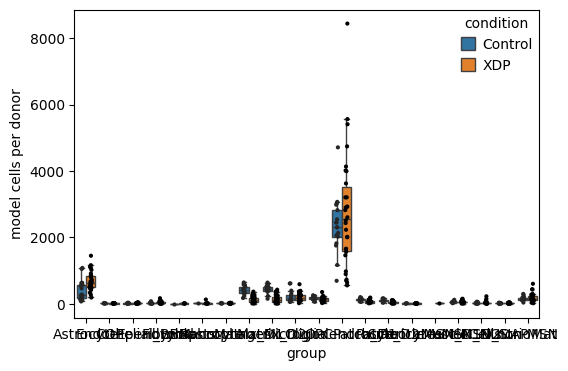

donors    sum  median
group             condition                       
Astrocyte         Control        17   7204   278.0
                  XDP            30  20510   633.5
COP               Control         5     89    16.0
                  XDP            11    180    13.0
Endothelial_BBB   Control         9    173    17.0
                  XDP            19    422    17.0
Ependymal         Control        10    249    17.5
                  XDP            24   1134    38.5
Fibroblasts       Control         1     12    12.0
                  XDP             4     57    13.0
Lymphocyte        Control         1     37    37.0
                  XDP             7    214    14.0
Macrophages       Control         6    122    20.5
                  XDP            26    550    20.5
Matrix_D1         Control        17   7213   413.0
                  XDP            29   3822   107.0
Matrix_D2         Control        17   7467   442.0
                  XDP            29   4270   113.0
Microglia         Control        17   3711   140.0
                  XDP            30   6157   189.0
OPC               Control        17   2866   179.0
                  XDP            30   4353   141.5
Oligodendrocyte   Control        17  40328  2305.0
                  XDP            30  82537  2561.0
Patch_D1          Control        17   2161   116.0
                  XDP            29   1933    54.0
Patch_D2          Control        17   1766    98.0
                  XDP            28   1397    45.0
Pericytes         Control         3     45    14.0
                  XDP             9    129    13.0
SmoothMuscleCells XDP             1     13    13.0
eMSN_D1D2         Control        17   1084    69.0
                  XDP            28   1733    57.0
eMSN_NUDAP        Control        11    317    21.0
                  XDP            20    946    26.5
eMSN_StrioMat     Control        15    302    18.0
                  XDP            23    535    19.0
non-MSN           Control        17   2755   152.0
                  XDP            30   5580   154.0

In [90]:
model_obs = obs[obs["in_model"]]
if RESPONSE_TYPE == "numeric":
    plt.figure(figsize=(10, 4))
    sns.boxplot(data=model_obs, x=DONOR_COL, y=RESPONSE, hue="group", showfliers=False)
    plt.xticks(rotation=45)
    plt.savefig(f"{OUT_DIR}/response_by_donor.png", dpi=150, bbox_inches="tight")
    plt.show()
else:
    # cells per donor in each level: the levels should not differ much
    per_donor = model_obs.groupby(["group", RESPONSE, DONOR_COL], observed=True).size().rename("cells").reset_index()
    plt.figure(figsize=(6, 4))
    sns.boxplot(data=per_donor, x="group", y="cells", hue=RESPONSE, showfliers=False)
    sns.stripplot(data=per_donor, x="group", y="cells", hue=RESPONSE, dodge=True, size=3, color="black", legend=False)
    plt.ylabel("model cells per donor")
    plt.savefig(f"{OUT_DIR}/cells_per_donor.png", dpi=150, bbox_inches="tight")
    plt.show()
    display(per_donor.groupby(["group", RESPONSE], observed=True)["cells"].agg(["count", "sum", "median"]).rename(columns={"count": "donors"}))

# Factors
Each group has its own factors (PC_1 of Matrix and PC_1 of Patch are different axes). `factor_names[group]` = the factors of the group; their scores go into `adata.obs`. Only the cell of the chosen `FACTOR_METHOD` does something.

### PCA
One PCA per group, from BICAN (loaded) or from the Control cells of this dataset (fitted here). Every cell of the group is projected onto it with `reference_pca.project_pca`: same normalisation, same HVGs, z-scored with the reference mean / SD, × loadings.

In [91]:
factor_names, scores = {}, []

if FACTOR_METHOD == "pca":
    pcas = {}
    for group in groups:
        if FACTORS_FROM == "bican":
            print("From Bican")
            pcas[group] = sc.read_h5ad(f"{BICAN_PCA_DIR}/{group}.h5ad")
        elif FACTORS_FROM == "healthy_samples":
            print("Fit PCA to new")
            # Control cells of the group, all Control donors (also those not in the model)
            healthy = adata[((adata.obs["group"] == group) & (adata.obs[CONDITION_COL] == HEALTHY_LEVEL)).values].copy()
            sc.pp.filter_genes(healthy, min_cells=MIN_CELLS_PER_GENE_REF)
            pcas[group] = reference_pca.fit_pca(healthy, n_hvg=N_HVG, n_pcs=N_PCS, target_sum=TARGET_SUM, seed=SEED)
        print(f"{group}: PCA from {pcas[group].n_obs} {FACTORS_FROM} cells, {pcas[group].var['highly_variable'].sum()} HVGs")

        # genes: the BICAN PCA uses gene names, with Ensembl IDs in var["gene_id"]; XDP var_names are Ensembl IDs
        match_on = "gene_id" if FACTORS_FROM == "bican" else None
        s = reference_pca.project_pca(adata[(adata.obs["group"] == group).values], pcas[group], match_on=match_on)
        factor_names[group] = list(s.columns)
        scores.append(s)

Fit PCA to new


/home/gdallagl/.pyenv/versions/3.11.8/lib/python3.11/functools.py:909: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)


Astrocyte: PCA from 7204 healthy_samples cells, 3000 HVGs
  27157/27157 PCA genes found, 3000/3000 HVGs
Fit PCA to new


/home/gdallagl/.pyenv/versions/3.11.8/lib/python3.11/functools.py:909: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)


COP: PCA from 156 healthy_samples cells, 3000 HVGs
  15283/15283 PCA genes found, 3000/3000 HVGs
Fit PCA to new


/home/gdallagl/.pyenv/versions/3.11.8/lib/python3.11/functools.py:909: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)


... (23 outputs left out)

/home/gdallagl/.pyenv/versions/3.11.8/lib/python3.11/functools.py:909: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)


eMSN_StrioMat: PCA from 317 healthy_samples cells, 3000 HVGs
  22440/22440 PCA genes found, 3000/3000 HVGs
Fit PCA to new


/home/gdallagl/.pyenv/versions/3.11.8/lib/python3.11/functools.py:909: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)


non-MSN: PCA from 2755 healthy_samples cells, 3000 HVGs
  30244/30244 PCA genes found, 3000/3000 HVGs


### cNMF
Spectra are trained outside this notebook (e.g. on UGER) on the reference counts. A group without a spectra file in `CNMF_SPECTRA` gets its reference counts written (healthy_samples), and the notebook stops. With spectra, each cell's usage is the non-negative least-squares fit of its counts (each gene divided by its SD in the reference counts) on the spectra, as in `nebula_with_factors`.

In [92]:
# if FACTOR_METHOD == "cnmf":
#     for group in groups:
#         # reference counts, with Ensembl IDs as var_names (as XDP)
#         if FACTORS_FROM == "bican":
#             ref = sc.read_h5ad(f"{BICAN_PCA_DIR}/cnmf_input/{group}.h5ad")          # BICAN gene names, IDs in var["gene_id"]
#             name_to_id = dict(zip(ref.var_names, ref.var["gene_id"]))
#             ref = ref[:, (ref.var["gene_id"] != "").values & ~ref.var["gene_id"].duplicated(keep=False).values].copy()
#             ref.var_names = ref.var["gene_id"].values
#         elif FACTORS_FROM == "healthy_samples":
#             ref = adata[((adata.obs["group"] == group) & (adata.obs[CONDITION_COL] == HEALTHY_LEVEL)).values].copy()
#             name_to_id = None

#         if group not in CNMF_SPECTRA:
#             if FACTORS_FROM == "healthy_samples":
#                 path = f"{OUT_DIR}/{group}/cnmf_input.h5ad"
#                 os.makedirs(os.path.dirname(path), exist_ok=True)
#                 ad.AnnData(ref.X.astype(np.float64), obs=ref.obs[[DONOR_COL]], var=ref.var[["gene_name"]]).write_h5ad(path)   # cNMF needs float64 counts
#             else:
#                 path = f"{BICAN_PCA_DIR}/cnmf_input/{group}.h5ad"
#             raise RuntimeError(f"no cNMF spectra for {group}: train cNMF on {path}, then add CNMF_SPECTRA['{group}']")

#         spectra = pd.read_csv(CNMF_SPECTRA[group], sep="\t", index_col=0)         # GEPs x genes
#         spectra.index = [f"GEP_{i + 1}" for i in range(len(spectra))]
#         if name_to_id is not None:
#             spectra.columns = [name_to_id.get(g, "") for g in spectra.columns]
#             spectra = spectra.loc[:, spectra.columns != ""]

#         print(f"{group}: cNMF {len(spectra)} GEPs, reference {ref.n_obs} {FACTORS_FROM} cells")
#         s = reference_pca.cnmf_usage(adata[(adata.obs["group"] == group).values], spectra, ref, normalise=CNMF_NORMALISE)
#         if CNMF_NORMALISE:
#             s = s.iloc[:, :-1]                    # fractions sum to 1: the last GEP is redundant
#         factor_names[group] = list(s.columns)
#         scores.append(s)

### DV score
Genes whose dorsal–ventral spatial gradient in BICAN is strong **and** agrees in sign in health and XDP (disease-invariant spatial markers), weight = mean ρ of the two. Each cell's score = z-scored log-normalised expression of these genes (within the group) × weights. The columns used for each group are `DV_GRADIENT_CT[group]`.

In [93]:
# if FACTOR_METHOD == "dv_score":
#     df_corr_health = pd.read_csv(f"{DV_CORR_DIR}/df_corr.csv", index_col=0)
#     df_corr_xdp = pd.read_csv(f"{DV_CORR_DIR}/df_corr_xdp.csv", index_col=0)
#     common_genes = df_corr_health.index.intersection(df_corr_xdp.index)
#     dfh, dfx = df_corr_health.loc[common_genes], df_corr_xdp.loc[common_genes]

#     # gene names -> XDP Ensembl IDs (names used by several IDs are left out)
#     names = adata.var["gene_name"]
#     name_to_id = dict(zip(names[~names.duplicated(keep=False)], names[~names.duplicated(keep=False)].index))

#     for group in groups:
#         ct = DV_GRADIENT_CT[group]
#         reliable = pd.Series(True, index=common_genes)
#         for d in [dfh, dfx]:
#             reliable &= (d[f"rho_{ct}"].abs() >= DV_MIN_ABS_RHO) & (d[f"padj_{ct}"] < DV_PADJ)
#             reliable &= (d[f"pct_expr_{ct}"] >= DV_MIN_PCT_EXPR) & (d[f"mean_expr_{ct}"] >= DV_MIN_MEAN_EXPR)
#         stable = reliable & (np.sign(dfh[f"rho_{ct}"]) == np.sign(dfx[f"rho_{ct}"]))
#         weights = (dfh.loc[stable, f"rho_{ct}"] + dfx.loc[stable, f"rho_{ct}"]) / 2
#         weights.index = [name_to_id.get(g, "") for g in weights.index]
#         weights = weights[weights.index != ""]

#         print(f"{group}: {stable.sum()} stable gradient genes ({ct})")
#         s = reference_pca.gradient_score(adata[(adata.obs["group"] == group).values], weights, target_sum=TARGET_SUM)
#         factor_names[group] = ["dv_score"]
#         scores.append(s.to_frame("dv_score"))

In [94]:
if FACTOR_METHOD != "none":
    scores = pd.concat(scores)
    adata.obs = adata.obs.drop(columns=scores.columns, errors="ignore").join(scores)
    display(adata.obs[["group", *scores.columns[:5]]].head())

,group,PC_1,PC_2,PC_3,PC_4,PC_5
barcode,,,,,,
A22KHKGLT3__pXDPsHSrPuiv1d240321rxn4__GTAGGCCTCCGTTGTC-1_Striatum_SCF-20-025,Astrocyte,0.229363,5.767706,1.337689,15.019554,-8.041378
A22KHKGLT3__pXDPsHSrPuiv1d240321rxn4__TCGGGACTCTCTGTCG-1_Striatum_SCF-22-054CM,Astrocyte,-5.697623,-0.537769,-0.286148,-2.990712,-4.513022
A22KHKGLT3__pXDPsHSrPuiv1d240321rxn4__CGGGTCACAAGAGGCT-1_Striatum_SCF-19-009,Astrocyte,-0.806473,0.246506,-2.429163,6.722050,-6.438794
A22KHKGLT3__pXDPsHSrPuiv1d240321rxn4__GGACATTGTAAACCTC-1_Striatum_SCF-22-054CM,Astrocyte,-7.402233,0.005103,0.331924,-2.609335,-3.664055
A22KHKGLT3__pXDPsHSrPuiv1d240321rxn4__ACGGAGACATACTACG-1_Striatum_SCF-20-025,Astrocyte,-0.885776,2.765921,-1.000954,8.540666,-4.983368


### Scree plot and knee (PCA only)

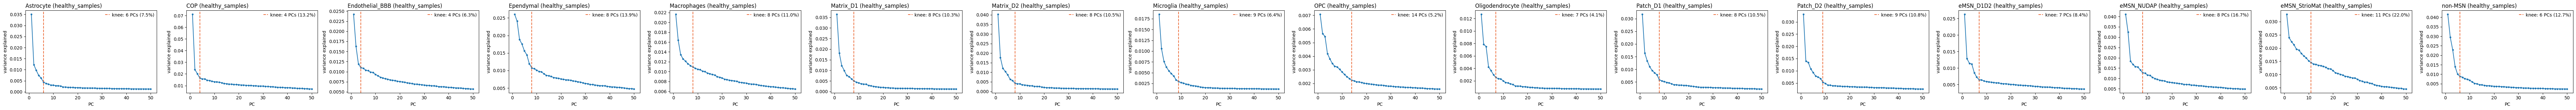

Astrocyte: candidate factors ['PC_1', 'PC_2', 'PC_3', 'PC_4', 'PC_5', 'PC_6']
COP: candidate factors ['PC_1', 'PC_2', 'PC_3', 'PC_4']
Endothelial_BBB: candidate factors ['PC_1', 'PC_2', 'PC_3', 'PC_4']
Ependymal: candidate factors ['PC_1', 'PC_2', 'PC_3', 'PC_4', 'PC_5', 'PC_6', 'PC_7', 'PC_8']
Macrophages: candidate factors ['PC_1', 'PC_2', 'PC_3', 'PC_4', 'PC_5', 'PC_6', 'PC_7', 'PC_8']
Matrix_D1: candidate factors ['PC_1', 'PC_2', 'PC_3', 'PC_4', 'PC_5', 'PC_6', 'PC_7', 'PC_8']
Matrix_D2: candidate factors ['PC_1', 'PC_2', 'PC_3', 'PC_4', 'PC_5', 'PC_6', 'PC_7', 'PC_8']
Microglia: candidate factors ['PC_1', 'PC_2', 'PC_3', 'PC_4', 'PC_5', 'PC_6', 'PC_7', 'PC_8', 'PC_9']
OPC: candidate factors ['PC_1', 'PC_2', 'PC_3', 'PC_4', 'PC_5', 'PC_6', 'PC_7', 'PC_8', 'PC_9', 'PC_10', 'PC_11', 'PC_12', 'PC_13', 'PC_14']
Oligodendrocyte: candidate factors ['PC_1', 'PC_2', 'PC_3', 'PC_4', 'PC_5', 'PC_6', 'PC_7']
Patch_D1: candidate factors ['PC_1', 'PC_2', 'PC_3', 'PC_4', 'PC_5', 'PC_6', 'PC_7', 

In [95]:
n_knee = {}
if FACTOR_METHOD == "pca":
    fig, axes = plt.subplots(1, len(pcas), figsize=(5 * len(pcas), 3.5), squeeze=False)
    for ax, (group, pca) in zip(axes[0], pcas.items()):
        evr = pca.uns["variance_ratio"]
        n_knee[group] = reference_pca.knee_point(evr)
        ax.plot(np.arange(1, len(evr) + 1), evr, "o-", ms=3)
        ax.axvline(n_knee[group], color="#eb6834", ls="--", label=f"knee: {n_knee[group]} PCs ({evr[:n_knee[group]].sum():.1%})")
        ax.set_xlabel("PC")
        ax.set_ylabel("variance explained")
        ax.set_title(f"{group} ({FACTORS_FROM})", loc="left")
        ax.legend()
    plt.tight_layout()
    plt.savefig(f"{OUT_DIR}/scree.png", dpi=150)
    plt.show()

# factors that can enter the model: PC_1 ... knee, or all GEPs / the DV score
candidates = {}
for group in groups:
    if FACTOR_METHOD == "pca":
        candidates[group] = factor_names[group][:n_knee[group]]
    else:
        candidates[group] = factor_names.get(group, [])
    print(f"{group}: candidate factors {candidates[group]}")

### Are the factors associated with the response?
For each factor, on the model cells of the group: `scale(factor) ~ RESPONSE + covariates + (1 | DONOR)`. `beta` = factor SDs per unit of the response (or tested vs baseline). "Associated" = FDR < `ASSOC_FDR` **and** |beta| ≥ `ASSOC_MIN_ABS_BETA` (with thousands of cells nearly every factor is significant).

An associated factor is either a **confounder** (adjusting is right) or is **moved by the response** (adjusting removes real signal): the data cannot tell the two apart. `FACTOR_ASSOCIATION` decides what to do with them; compare the factor model with the baseline.

`candidate` = the factor can enter the model (PCA: up to the knee). `var_ratio` (PCA) = variance of the PC in the model cells / in the reference: much less than 1 means the axis barely varies here.

In [96]:
# name of the tested term in statsmodels
response_param = RESPONSE if RESPONSE_TYPE == "numeric" else f"{RESPONSE}[T.{RESPONSE_TESTED}]"

assoc = {}
if FACTOR_METHOD != "none":
    for group in groups:
        cells = adata.obs[adata.obs["in_model"] & (adata.obs["group"] == group)].copy()
        to_test = factor_names[group]
        if FACTOR_METHOD == "pca":
            to_test = to_test[:max(N_PCS_TO_TEST, n_knee[group])]

        rows = []
        for i, f in enumerate(to_test):
            cells["y"] = (cells[f] - cells[f].mean()) / cells[f].std()
            formula = "y ~ " + " + ".join([RESPONSE, *covariates[group]])
            with warnings.catch_warnings():
                warnings.simplefilter("ignore")
                fit = smf.mixedlm(formula, cells, groups=cells[DONOR_COL]).fit()
            row = {"factor": f, "beta": fit.params[response_param], "se": fit.bse[response_param],
                   "p": fit.pvalues[response_param], "candidate": f in candidates[group]}
            if FACTOR_METHOD == "pca":
                row["var_ratio"] = cells[f].var() / pcas[group].obsm["X_pca"][:, i].var()
            rows.append(row)

        a = pd.DataFrame(rows).set_index("factor")
        a["fdr"] = multipletests(a["p"], method="fdr_bh")[1]
        a["associated"] = (a["fdr"] < ASSOC_FDR) & (a["beta"].abs() >= ASSOC_MIN_ABS_BETA)
        a.to_csv(f"{OUT_DIR}/{group}_factor_association.csv")
        assoc[group] = a
        print(f"{group}: candidate factors associated with {RESPONSE}: {a.index[a['candidate'] & a['associated']].tolist()}")

    # beta with 95% CI; orange = associated; dashed line = end of the candidates (PCA: knee)
    fig, axes = plt.subplots(1, len(assoc), figsize=(max(6, 0.4 * len(a)) * len(assoc), 3.5), squeeze=False)
    for ax, (group, a) in zip(axes[0], assoc.items()):
        ax.bar(a.index, a["beta"], yerr=1.96 * a["se"], color=np.where(a["associated"], "#eb6834", "#b8b7b2"))
        ax.axhline(0, color="black", lw=0.8)
        ax.axvline(a["candidate"].sum() - 0.5, color="#52514e", ls="--", lw=0.8)
        ax.set_ylabel("beta (factor SDs)")
        ax.set_title(f"{group} ({FACTOR_METHOD}, {FACTORS_FROM}): factor ~ {RESPONSE}", loc="left")
        ax.tick_params(axis="x", rotation=60)
    plt.tight_layout()
    plt.savefig(f"{OUT_DIR}/factor_association.png", dpi=150)
    plt.show()

pd.concat(assoc, axis=1).round(3) if assoc else None

Astrocyte: candidate factors associated with condition: ['PC_1']


LinAlgError: Singular matrix

# Models
`baseline` has no factors. The factor model has the candidate factors, filtered by `FACTOR_ASSOCIATION`.

In [ ]:
factor_model_name = {"pca": "pca_knee", "cnmf": "cnmf", "dv_score": "dv_score"}.get(FACTOR_METHOD)
if FACTOR_ASSOCIATION != "all":
    factor_model_name += f"_{FACTOR_ASSOCIATION}"

models = {}
for group in groups:
    models[group] = {"baseline": []}
    if FACTOR_METHOD != "none":
        chosen = candidates[group]
        if FACTOR_ASSOCIATION == "only_associated":
            chosen = [f for f in chosen if assoc[group].loc[f, "associated"]]
        elif FACTOR_ASSOCIATION == "drop_associated":
            chosen = [f for f in chosen if not assoc[group].loc[f, "associated"]]
        models[group][factor_model_name] = chosen

    for name, factors in models[group].items():
        print(f"{group} / {name}: counts ~ {' + '.join([RESPONSE, *covariates[group], *factors])} + (1|{DONOR_COL})")

MSN / baseline: counts ~ condition + age_of_death + sex + pct_counts_mt + frac_intronic + cohort + msn_subtype + (1|donor_id)
MSN / pca_knee: counts ~ condition + age_of_death + sex + pct_counts_mt + frac_intronic + cohort + msn_subtype + PC_1 + PC_2 + PC_3 + PC_4 + PC_5 + PC_6 + PC_7 + (1|donor_id)


# Genes tested and design
Per group, on its model cells: a gene is tested if detected in ≥ n_donors × `MIN_CELLS_PER_DONOR` cells **and** ≥ `MIN_COUNTS_PER_GENE` counts. Handsaker phase genes (`FORCE_KEEP_PHASES`) are tested anyway if detected in ≥ 1 cell: their estimates can be unreliable, check `forced_gene` and `n_cells_detected` in the results.

Columns in `STANDARDISE` (and the factors, if `STANDARDISE_FACTORS`) are z-scored over the model cells: only their own coefficients change, not the tested one.

In [ ]:
force_keep_genes = []
for phase in FORCE_KEEP_PHASES:
    force_keep_genes += pd.read_csv(f"{HANDSAKER_GENES_DIR}/phase_{phase}_genes.csv")["Gene"].tolist()

m, gene_table = {}, {}
for group in groups:
    mc = adata[(adata.obs["in_model"] & (adata.obs["group"] == group)).values].copy()
    factors = factor_names.get(group, [])

    # genes
    min_cells = mc.obs[DONOR_COL].nunique() * MIN_CELLS_PER_DONOR
    g = pd.DataFrame({
        "gene_name": mc.var["gene_name"],
        "n_cells_detected": np.asarray((mc.X > 0).sum(axis=0)).ravel(),
        "total_counts": np.asarray(mc.X.sum(axis=0)).ravel(),
    })
    passes = (g["n_cells_detected"] >= min_cells) & (g["total_counts"] >= MIN_COUNTS_PER_GENE)
    g["forced_gene"] = ~passes & g["gene_name"].isin(force_keep_genes) & (g["n_cells_detected"] >= 1)
    g = g[passes | g["forced_gene"]]
    print(f"{group}: {passes.sum()} genes pass the filter + {g['forced_gene'].sum()} forced = {len(g)} tested")

    # design
    for c in covariates[group]:
        if COVARIATES[c] == "categorical":
            mc.obs[c] = mc.obs[c].astype(str)
    to_standardise = [c for c in STANDARDISE if c in covariates[group]] + (factors if STANDARDISE_FACTORS else [])
    for c in to_standardise:
        mc.obs[c] = (mc.obs[c] - mc.obs[c].mean()) / mc.obs[c].std()

    m[group] = mc[:, g.index].copy()
    gene_table[group] = g
    os.makedirs(f"{OUT_DIR}/{group}", exist_ok=True)
    g.to_csv(f"{OUT_DIR}/{group}/genes_tested.csv")
    mc.obs[[DONOR_COL, LIBRARY_SIZE_COL, RESPONSE, *covariates[group], *factors]].to_csv(f"{OUT_DIR}/{group}/design_table.csv")

MSN: 21838 genes pass the filter + 76 forced = 21914 tested


# NEBULA
For each group and model. `nebula_runner.finalise` adds gene names, `log2FC_<coef>` (NEBULA reports natural log), `converged` (convergence code 1) and the BH FDR over the converged genes.

`baseline` is loaded from `BASELINE_DIR` (fitted by an earlier run) if `REUSE_BASELINE` and it was fitted on the same cells, genes, design and NEBULA settings (`fingerprint.txt`); otherwise it is fitted and saved there.

In [ ]:
results = {}
for group in groups:
    results[group] = {}
    for name, factors in models[group].items():
        print(f"\n######## {group} / {name}")
        terms = [RESPONSE, *covariates[group], *factors]
        types = {RESPONSE: RESPONSE_TYPE, **{c: COVARIATES[c] for c in covariates[group]}, **{f: "numeric" for f in factors}}

        # what a fit depends on: cells, genes, design values, NEBULA settings
        design = m[group].obs[[DONOR_COL, LIBRARY_SIZE_COL, *terms]].astype(str)
        fingerprint = (f"{pd.util.hash_pandas_object(design).sum()}_{pd.util.hash_pandas_object(pd.Series(m[group].var_names)).sum()}"
                       f"_{NEBULA_METHOD}_{NEBULA_CPC}_{NEBULA_MINCP}")
        shared = f"{BASELINE_DIR}/{group}"
        reuse = (name == "baseline" and REUSE_BASELINE and os.path.exists(f"{shared}/fingerprint.txt")
                 and open(f"{shared}/fingerprint.txt").read() == fingerprint)

        if reuse:
            print(f"  baseline loaded from {shared} (same cells, genes and design)")
            res = pd.read_csv(f"{shared}/deg_results.csv")
        else:
            raw = nebula_runner.run(m[group], terms, types, donor_col=DONOR_COL, offset_col=LIBRARY_SIZE_COL,
                                    method=NEBULA_METHOD, n_folds=N_FOLDS, n_cores=N_CORES,
                                    cpc=NEBULA_CPC, mincp=NEBULA_MINCP, tmp_dir=f"{OUT_DIR}/tmp")
            res = nebula_runner.finalise(raw, gene_table[group], coef=coef, convergence_ok=[1], fdr=FDR)
            if name == "baseline":
                os.makedirs(shared, exist_ok=True)
                res.to_csv(f"{shared}/deg_results.csv", index=False)
                open(f"{shared}/fingerprint.txt", "w").write(fingerprint)

        os.makedirs(f"{OUT_DIR}/{group}/{name}", exist_ok=True)
        res.to_csv(f"{OUT_DIR}/{group}/{name}/deg_results.csv", index=False)
        results[group][name] = res


######## MSN / baseline
  baseline loaded from /home/gdallagl/myworkdir/XDP/data/XDP/NucSec/DEG/Striatum/nebula_v2/condition__baseline/MSN (same cells, genes and design)

######## MSN / pca_knee
NEBULA-LN: 21914 genes x 30051 cells, 47 donors, 40 chunks on 40 cores; formula ~ condition + age_of_death + sex + pct_counts_mt + frac_intronic + cohort + msn_subtype + PC_1 + PC_2 + PC_3 + PC_4 + PC_5 + PC_6 + PC_7 + (1|donor_id), offset total_counts
  4/40 chunks done
  8/40 chunks done
  12/40 chunks done
  16/40 chunks done
  20/40 chunks done
  24/40 chunks done
  28/40 chunks done
  32/40 chunks done
  36/40 chunks done
  40/40 chunks done
  21914 genes fitted (0 removed by NEBULA cpc/mincp), 21169 converged; 336 with FDR < 0.05


In [ ]:
# # results of an earlier run, without fitting again (run this instead of the cell above)
# results = {group: {name: pd.read_csv(f"{OUT_DIR}/{group}/{name}/deg_results.csv") for name in models[group]}
#            for group in groups}

# Results

In [ ]:
LFC = f"log2FC_{coef}"
P = f"p_{coef}"
P_ADJ = f"fdr_{coef}"

summary = []
for group in results:
    for name, r in results[group].items():
        sig = r[P_ADJ] < FDR
        summary.append({"group": group, "model": name, "n_factors": len(models[group][name]), "genes": len(r),
                        "converged": r["converged"].sum(), f"FDR < {FDR}": sig.sum(),
                        "up": (sig & (r[LFC] > 0)).sum(), "down": (sig & (r[LFC] < 0)).sum()})
summary = pd.DataFrame(summary)
summary.to_csv(f"{OUT_DIR}/summary_n_degs.csv", index=False)
summary

,group,model,n_factors,genes,converged,FDR < 0.05,up,down
0,MSN,baseline,0,21914,21177,2606,1837,769
1,MSN,pca_knee,7,21914,21169,336,138,198


### Factor model vs baseline
Converged genes. Blue = significant in both, orange = baseline only, green = factor model only. Points below the diagonal: the factors absorb part of the effect.

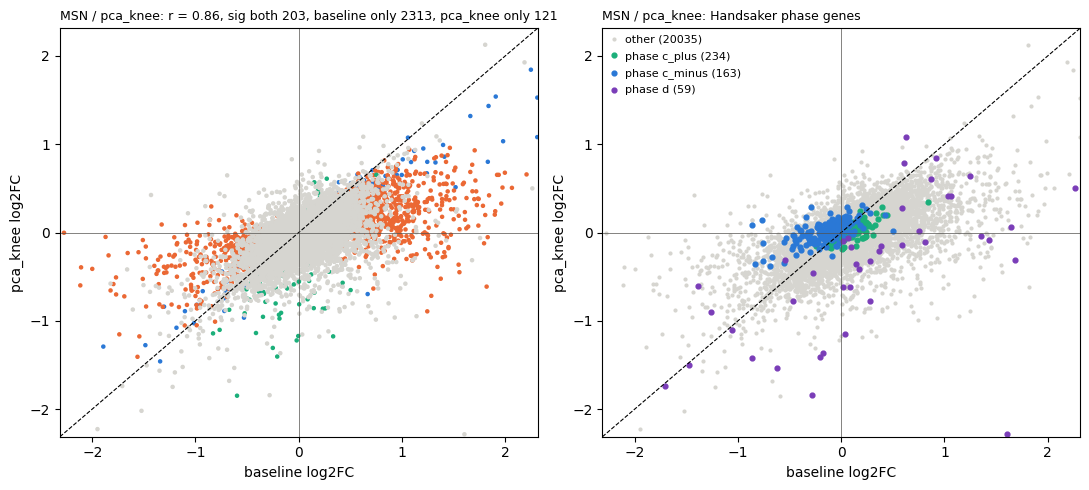

In [ ]:
# Handsaker phase genes (gene names)
phase_colors = {"c_plus": "#1baf7a", "c_minus": "#2a78d6", "d": "#7a3db8"}
phase_genes = {phase: pd.read_csv(f"{HANDSAKER_GENES_DIR}/phase_{phase}_genes.csv")["Gene"] for phase in phase_colors}

for group in results:
    other = [name for name in results[group] if name != "baseline"]
    if not other:
        continue
    # one row per factor model: left = coloured by significance, right = coloured by Handsaker phase
    fig, axes = plt.subplots(len(other), 2, figsize=(11, 5 * len(other)), squeeze=False)
    for (ax1, ax2), name in zip(axes, other):
        both = results[group]["baseline"].merge(results[group][name], on="gene_id", suffixes=("_base", "_model"))
        both = both[both["converged_base"] & both["converged_model"]]
        x, y = both[f"{LFC}_base"], both[f"{LFC}_model"]
        sig_base, sig_model = both[f"{P_ADJ}_base"] < FDR, both[f"{P_ADJ}_model"] < FDR
        lim = pd.concat([x, y]).abs().quantile(0.999)
        r = np.corrcoef(x, y)[0, 1]

        # significance
        color = np.select([sig_base & sig_model, sig_base, sig_model], ["#2a78d6", "#eb6834", "#1baf7a"], "#d6d5d0")
        ax1.scatter(x, y, s=5, c=color)
        ax1.set_title(f"{group} / {name}: r = {r:.2f}, sig both {(sig_base & sig_model).sum()}, "
                      f"baseline only {(sig_base & ~sig_model).sum()}, {name} only {(~sig_base & sig_model).sum()}", fontsize=9, loc="left")

        # Handsaker phase: other genes grey, phase genes on top
        in_any = both["gene_name_base"].isin(pd.concat(phase_genes.values()))
        ax2.scatter(x[~in_any], y[~in_any], s=4, c="#d6d5d0", label=f"other ({(~in_any).sum()})")
        for phase, col in phase_colors.items():
            in_phase = both["gene_name_base"].isin(phase_genes[phase])
            ax2.scatter(x[in_phase], y[in_phase], s=12, c=col, label=f"phase {phase} ({in_phase.sum()})")
        ax2.legend(fontsize=8, loc="upper left")
        ax2.set_title(f"{group} / {name}: Handsaker phase genes", fontsize=9, loc="left")

        for ax in (ax1, ax2):
            ax.plot([-lim, lim], [-lim, lim], "k--", lw=0.8)
            ax.axhline(0, color="#52514e", lw=0.5)
            ax.axvline(0, color="#52514e", lw=0.5)
            ax.set_xlim(-lim, lim)
            ax.set_ylim(-lim, lim)
            ax.set_xlabel("baseline log2FC")
            ax.set_ylabel(f"{name} log2FC")
    plt.tight_layout()
    plt.savefig(f"{OUT_DIR}/{group}_models_vs_baseline.png", dpi=150)
    plt.show()


### Volcano plots with gene sets
Per group, one row per model: Handsaker phase genes, healthy dorsal–ventral gradient of each gene (`mean_spearman`, red / blue = up / down along the gradient), top genes. |log2FC| above `MAX_X` is drawn at the edge.

/home/gdallagl/myworkdir/XDP/utils/DEG.py:955: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(loc='upper right', frameon=False)
/home/gdallagl/myworkdir/XDP/utils/DEG.py:955: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(loc='upper right', frameon=False)


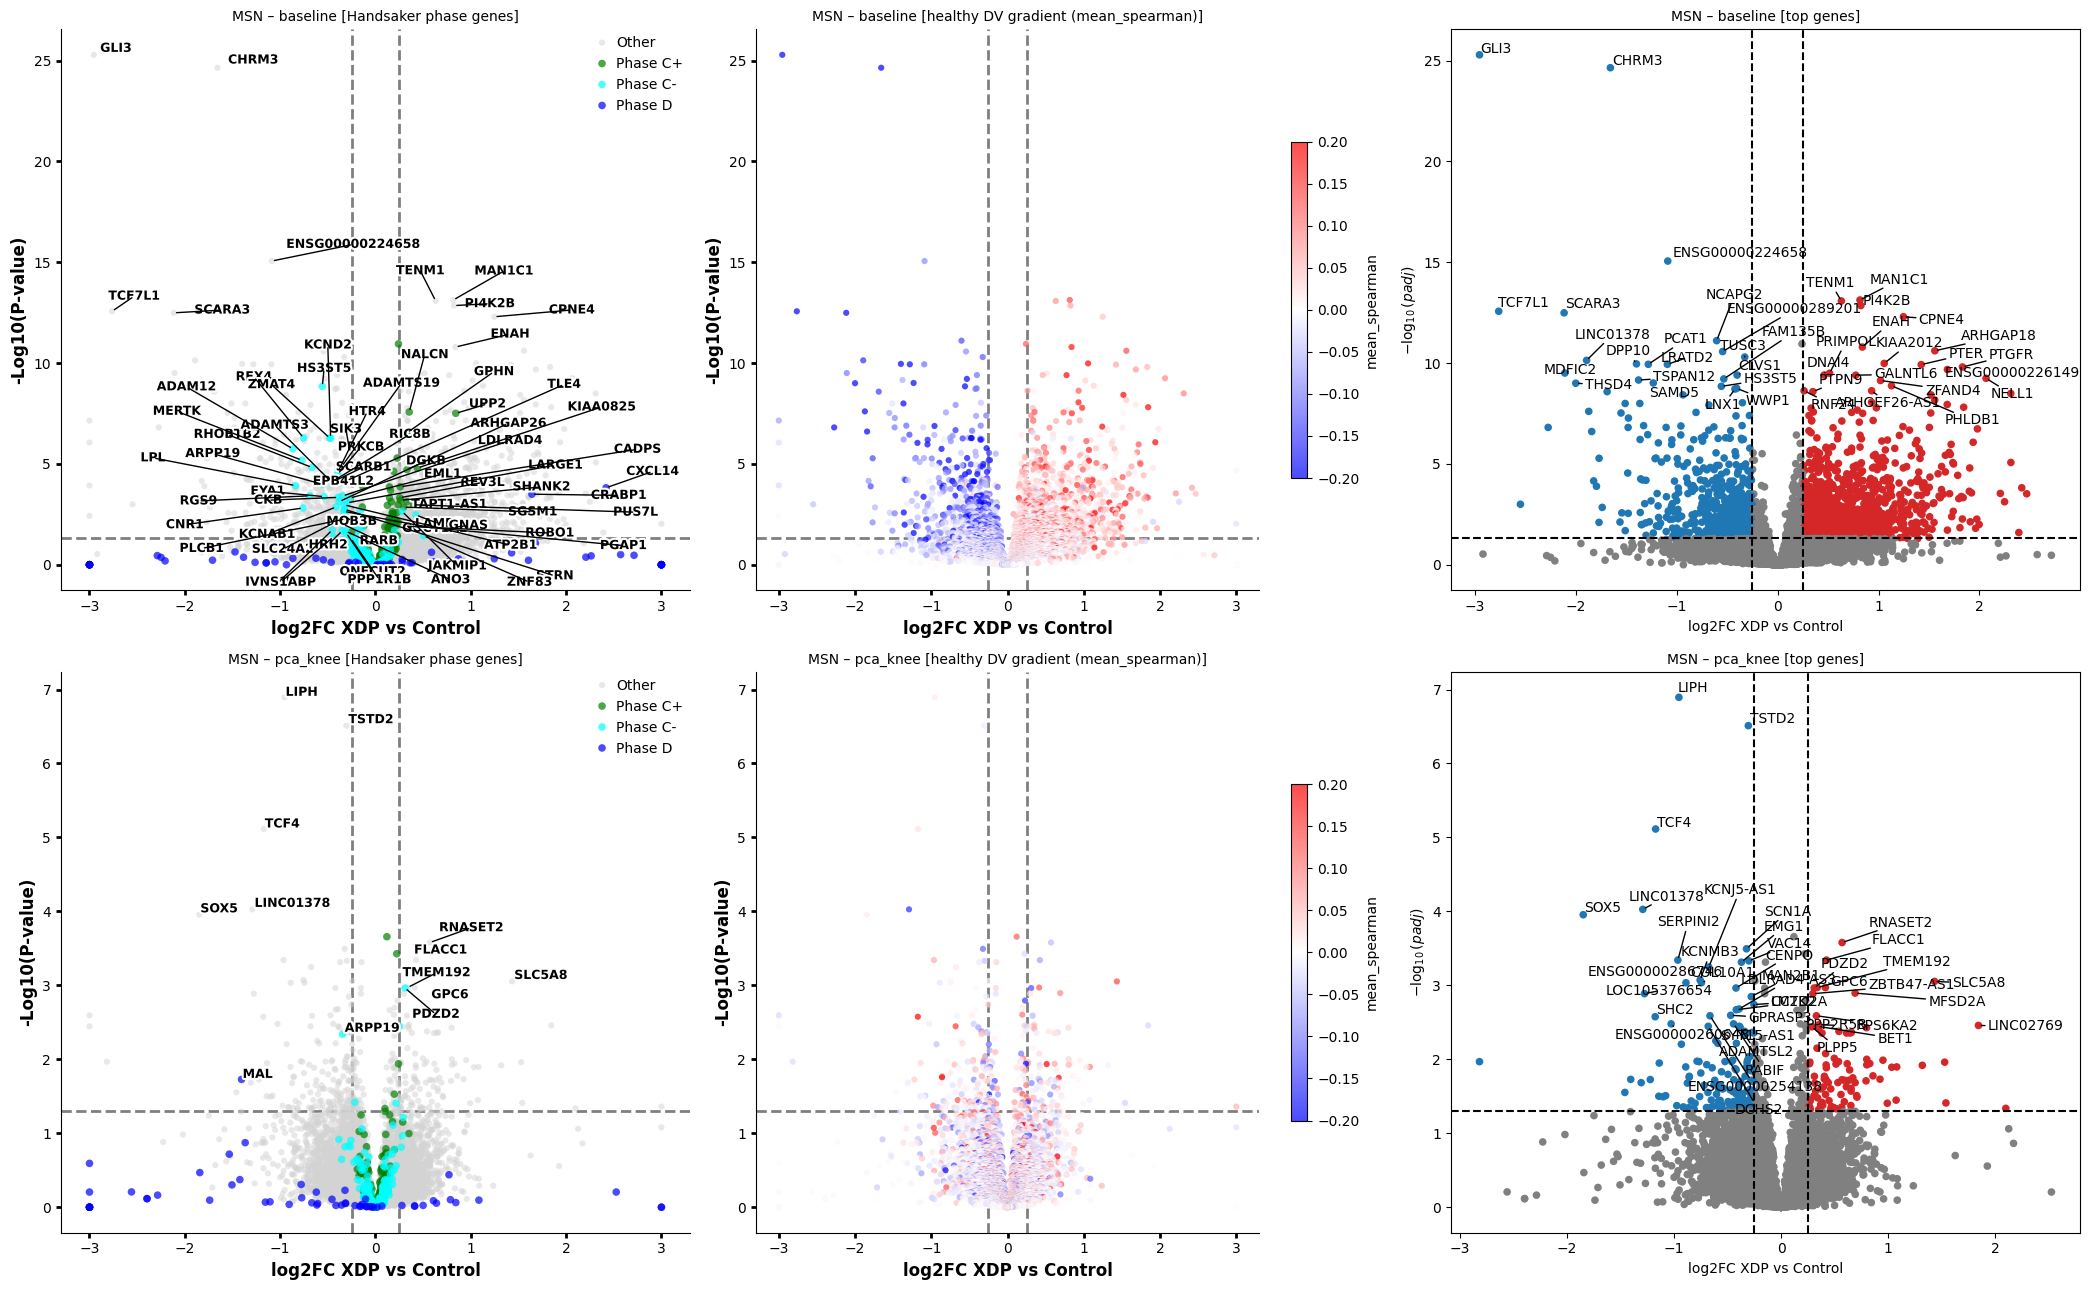

In [ ]:
# Handsaker phase genes and healthy dorsal-ventral gradient

phase_colors = {"c_plus": "#1baf7a", "c_minus": "#2a78d6", "d": "#7a3db8"}
phase_genes = {phase: pd.read_csv(f"{HANDSAKER_GENES_DIR}/phase_{phase}_genes.csv")["Gene"] for phase in phase_colors}
x_label = f"log2FC per unit of {RESPONSE}" if RESPONSE_TYPE == "numeric" else f"log2FC {RESPONSE_TESTED} vs {RESPONSE_BASELINE}"

categories_handsaker_phases = {
    "Phase D":  (pd.read_csv(f"{HANDSAKER_GENES_DIR}/phase_d_genes.csv")["Gene"].tolist(), "blue"),
    "Phase C+": (pd.read_csv(f"{HANDSAKER_GENES_DIR}/phase_c_plus_genes.csv")["Gene"].tolist(), "green"),
    "Phase C-": (pd.read_csv(f"{HANDSAKER_GENES_DIR}/phase_c_minus_genes.csv")["Gene"].tolist(), "cyan"),
}
df_grad = pd.read_csv("/home/gdallagl/myworkdir/XDP/utils/dorsal_ventral_gradient/exp_by_spline_combined.csv").set_index("gene")

for group in results:
    fig, axes = plt.subplots(len(results[group]), 3, figsize=(21, 6.5 * len(results[group])), squeeze=False)

    for row, (name, r) in zip(axes, results[group].items()):
        # converged genes, with the healthy gradient of each gene; log2FC clipped at MAX_X
        df = r[r["converged"]].merge(df_grad[["mean_spearman"]], how="left", left_on="gene_name", right_index=True)
        df_plot = df.assign(**{LFC: df[LFC].clip(-MAX_X, MAX_X)})
        ax1, ax2, ax3 = row

        DEG.plot_vulcano(df_plot, logfc_col=LFC, pval_col=P_ADJ, gene_col="gene_name",
                         pval_thresh=FDR, logfc_thresh=LOGFC_THR, to_label=5,
                         categories=categories_handsaker_phases, max_y=None, ax=ax1, print_labels=True)
        DEG.plot_vulcano(df_plot, logfc_col=LFC, pval_col=P_ADJ, gene_col="gene_name",
                         pval_thresh=FDR, logfc_thresh=LOGFC_THR, to_label=0,
                         color_by="mean_spearman", cmap="bwr", vmin=-0.2, vmax=0.2,
                         max_y=None, ax=ax2, print_labels=False)
        # top genes labelled (gene names can repeat across Ensembl IDs: keep the most significant)
        top = df.sort_values(P_ADJ).drop_duplicates("gene_name").set_index("gene_name")
        dc.pl.volcano(top.rename(columns={P_ADJ: "padj", LFC: "logFC"}),
                      x="logFC", y="padj", top=40, thr_stat=LOGFC_THR, thr_sign=FDR, max_stat=MAX_X, ax=ax3)

        for ax, lbl in zip(row, ["Handsaker phase genes", "healthy DV gradient (mean_spearman)", "top genes"]):
            ax.set_title(f"{group} – {name} [{lbl}]", fontsize=10)
            ax.set_xlabel(x_label)

    plt.tight_layout()
    plt.savefig(f"{OUT_DIR}/{group}_volcano_all_models.png", dpi=150, bbox_inches="tight")
    plt.show()

### Factor model vs baseline: how much of the effect goes through the factors
For each gene, the baseline effect splits into the effect at a fixed factor value plus a part through the factors:

```
log2FC_baseline  ≈  log2FC_model  +  sum_k log2FC_factor_k(gene) * delta_k
```

`delta_k` = shift of factor k (as in the NEBULA design) between `RESPONSE_TESTED` and `RESPONSE_BASELINE` (numeric: per unit of the response), from the LMM `factor_k ~ response + covariates + (1|donor)` on the design table of the group.
* `log2FC_model` = response effect at fixed position on the factors.
* `sum_k log2FC_factor_k * delta_k` = positional component: confounding (e.g. XDP donors with different cell composition along the factor) OR a disease effect that moves cells along the factors. The data cannot separate the two.

`corr(baseline - adjusted, positional component)` should be close to 1: otherwise the decomposition does not hold well for that model.

In [ ]:
phase_of_gene = {g: label for phase, label in [("c_plus", "C+"), ("c_minus", "C-"), ("d", "D")]
                 for g in pd.read_csv(f"{HANDSAKER_GENES_DIR}/phase_{phase}_genes.csv")["Gene"]}

decomp = {}
for group in results:
    design = pd.read_csv(f"{OUT_DIR}/{group}/design_table.csv", index_col=0)
    if RESPONSE_TYPE == "categorical":
        design[RESPONSE] = pd.Categorical(design[RESPONSE].astype(str), categories=[RESPONSE_BASELINE, RESPONSE_TESTED])
    rhs = " + ".join([RESPONSE, *covariates[group]])
    base = results[group]["baseline"].set_index("gene_id")

    for name, factors in models[group].items():
        if name == "baseline" or not factors:
            continue
        model = results[group][name].set_index("gene_id")

        # delta_k of each factor
        delta = {}
        for f in factors:
            with warnings.catch_warnings():
                warnings.simplefilter("ignore")
                fit = smf.mixedlm(f"{f} ~ {rhs}", design, groups=design[DONOR_COL]).fit(reml=True)
            delta[f] = {"delta": fit.params[response_param], "p": fit.pvalues[response_param]}

        # genes converged in both models
        g = base.index[base["converged"]].intersection(model.index[model["converged"]])
        d = pd.DataFrame({
            "gene_name": model.loc[g, "gene_name"],
            "logFC_baseline": base.loc[g, LFC],
            "logFC_adjusted": model.loc[g, LFC],
            "positional_component": sum(model.loc[g, f"log2FC_{f}"] * delta[f]["delta"] for f in factors),
            "sig_baseline": base.loc[g, P_ADJ] < FDR,
            "sig_adjusted": model.loc[g, P_ADJ] < FDR,
            "n_cells_detected": model.loc[g, "n_cells_detected"],
        })
        d["mean_spearman"] = d["gene_name"].map(df_grad["mean_spearman"])
        d["phase"] = d["gene_name"].map(phase_of_gene).fillna("")
        only = f"revealed by adjustment ({name} only)"
        d["category"] = np.select(
            [d.sig_baseline & d.sig_adjusted & (np.sign(d.logFC_baseline) == np.sign(d.logFC_adjusted)),
             d.sig_baseline & ~d.sig_adjusted,
             ~d.sig_baseline & d.sig_adjusted],
            ["robust (both)", "position-dependent (baseline only)", only],
            "not significant")
        decomp[(group, name)] = d
        d.to_csv(f"{OUT_DIR}/{group}/{name}/response_effect_position_decomposition.csv")

        check = np.corrcoef(d.logFC_baseline - d.logFC_adjusted, d.positional_component)[0, 1]
        print(f"\n######## {group} / {name}: {len(factors)} factors; corr(baseline - adjusted, positional component) = {check:.2f}")
        display(pd.DataFrame(delta).T.rename(columns={"delta": "delta (factor units)"}).round(4))
        display(pd.crosstab(d["category"], d["phase"].replace("", "other"), margins=True))


######## MSN / pca_knee: 7 factors; corr(baseline - adjusted, positional component) = 0.93


,delta (factor units),p
PC_1,-0.5156,0.0006
PC_2,-0.7095,0.0000
PC_3,-0.3400,0.0149
PC_4,-0.1614,0.1172
PC_5,-0.3780,0.0021
PC_6,0.3606,0.0042
PC_7,0.1373,0.4465


phase,C+,C-,D,other,All
category,,,,,
not significant,185,115,55,17500,17855
position-dependent (baseline only),44,43,3,2223,2313
revealed by adjustment (pca_knee only),1,1,1,118,121
robust (both),4,4,0,194,202
All,234,163,59,20035,20491


In [ ]:
for (group, name), d in decomp.items():
    print(f"\n######## {group} / {name}")
    for cat in ["robust (both)", "position-dependent (baseline only)", f"revealed by adjustment ({name} only)"]:
        top = d[d["category"] == cat]
        top = top.reindex(top["logFC_baseline"].abs().sort_values(ascending=False).index)
        print(f"{cat}: {len(top)} genes")
        display(top.head(50)[["gene_name", "logFC_baseline", "logFC_adjusted", "positional_component",
                              "mean_spearman", "phase", "n_cells_detected"]].round(3))


######## MSN / pca_knee
robust (both): 202 genes


,gene_name,logFC_baseline,logFC_adjusted,positional_component,mean_spearman,phase,n_cells_detected
gene_id,,,,,,,
ENSG00000229051,LINC01788,-3.946,-2.818,-0.827,-0.027,,568
ENSG00000203837,PNLIPRP3,-3.596,-3.991,0.866,-0.004,,622
ENSG00000285724,ENSG00000285724,3.431,2.100,1.060,-0.008,,509
ENSG00000250453,ENSG00000250453,-3.245,-3.122,-0.091,-0.029,,802
LOC101927847,LOC101927847,2.312,1.529,1.679,NaN,,3360
ENSG00000100095,SEZ6L,2.311,1.081,1.455,0.099,,7292
ENSG00000259815,LINC02769,2.249,1.844,-0.198,-0.034,,2044
ENSG00000136155,SCEL,1.980,1.034,0.926,0.022,,1105
ENSG00000261453,LINC01735,1.909,1.540,-0.100,-0.036,,4119


position-dependent (baseline only): 2313 genes


,gene_name,logFC_baseline,logFC_adjusted,positional_component,mean_spearman,phase,n_cells_detected
gene_id,,,,,,,
ENSG00000225537,ENSG00000225537,-5.075,-1.129,-3.535,-0.075,,819
ENSG00000238100,HCG24,3.858,3.401,0.401,-0.023,,1300
ENSG00000106571,GLI3,-2.954,-0.319,-2.796,-0.351,,8577
ENSG00000152284,TCF7L1,-2.763,-0.345,-1.919,-0.270,,5453
ENSG00000287865,ENSG00000287865,-2.548,-1.639,-0.659,-0.049,,5153
ENSG00000179299,NSUN7,2.468,0.308,2.075,0.052,,514
ENSG00000145824,CXCL14,2.419,0.772,1.804,0.073,D,392
LOC124900636,LOC124900636,2.390,2.172,0.245,NaN,,490
ENSG00000240045,STRIT1,-2.274,-0.003,-2.111,-0.211,,1802


revealed by adjustment (pca_knee only): 121 genes


,gene_name,logFC_baseline,logFC_adjusted,positional_component,mean_spearman,phase,n_cells_detected
gene_id,,,,,,,
ENSG00000186340,THBS2,-0.830,-1.143,0.083,-0.021,,702
ENSG00000198732,SMOC1,-0.766,-1.102,0.300,-0.004,,1738
ENSG00000290969,ENSG00000290969,0.752,0.654,0.226,-0.008,,1912
ENSG00000156076,WIF1,-0.673,-0.875,0.277,0.015,,491
ENSG00000134532,SOX5,-0.597,-1.849,1.483,0.017,,643
ENSG00000133067,LGR6,-0.524,-0.915,0.171,-0.080,,738
ENSG00000081985,IL12RB2,-0.506,-0.644,0.193,-0.008,,1405
ENSG00000137478,FCHSD2,0.503,-0.652,1.047,0.136,,12867
ENSG00000250961,RMEL3,-0.495,-0.750,0.129,0.018,,1763


# PCs BICAN Vs PCs Helthy

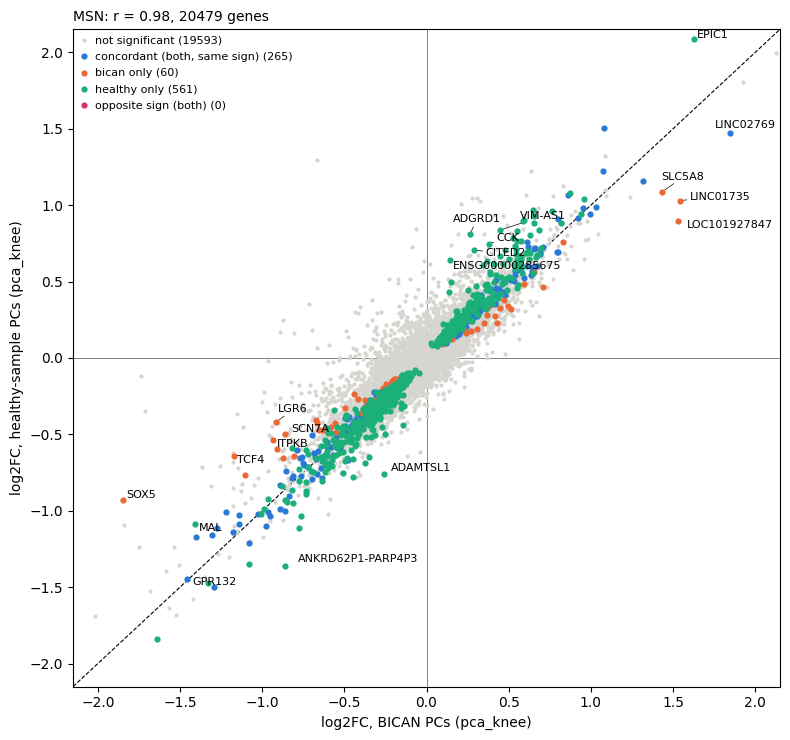


######## MSN


phase,C+,C-,D,other,All
category,,,,,
bican only,0,0,0,60,60
"concordant (both, same sign)",5,5,1,254,265
healthy only,3,9,0,549,561
not significant,231,148,57,19157,19593
All,239,162,58,20020,20479


concordant (both, same sign): 265 genes


,gene_name,log2FC_bican,log2FC_healthy,fdr_bican,fdr_healthy,phase,n_cells_detected,forced_gene
gene_id,,,,,,,,
ENSG00000291111,ENSG00000291111,4.462,4.782,0.044,0.016,,2728,False
ENSG00000203837,PNLIPRP3,-3.991,-2.697,0.004,0.017,,622,False
ENSG00000250453,ENSG00000250453,-3.122,-3.008,0.003,0.003,,802,False
ENSG00000229051,LINC01788,-2.818,-2.852,0.011,0.009,,568,False
ENSG00000285724,ENSG00000285724,2.100,2.556,0.046,0.004,,509,False
ENSG00000259815,LINC02769,1.844,1.475,0.003,0.021,,2044,False
ENSG00000183484,GPR132,-1.460,-1.444,0.028,0.022,,577,False
ENSG00000172005,MAL,-1.405,-1.174,0.019,0.046,D,137,True
ENSG00000259668,ENSG00000259668,1.320,1.156,0.012,0.012,,1229,False


opposite sign (both): 0 genes


,gene_name,log2FC_bican,log2FC_healthy,fdr_bican,fdr_healthy,phase,n_cells_detected,forced_gene
gene_id,,,,,,,,


bican only: 60 genes


,gene_name,log2FC_bican,log2FC_healthy,fdr_bican,fdr_healthy,phase,n_cells_detected,forced_gene
gene_id,,,,,,,,
ENSG00000134532,SOX5,-1.849,-0.933,0.000,0.178,,643,False
LOC101927847,LOC101927847,1.529,0.897,0.011,0.140,,3360,False
ENSG00000196628,TCF4,-1.172,-0.639,0.000,0.090,,1078,False
ENSG00000261453,LINC01735,1.540,1.030,0.039,0.219,,4119,False
ENSG00000133067,LGR6,-0.915,-0.419,0.044,0.346,,738,False
ENSG00000143772,ITPKB,-0.932,-0.535,0.006,0.173,,1222,False
ENSG00000136546,SCN7A,-0.863,-0.500,0.045,0.359,,1005,False
ENSG00000256870,SLC5A8,1.434,1.087,0.001,0.176,,2670,False
ENSG00000198732,SMOC1,-1.102,-0.767,0.032,0.067,,1738,False


healthy only: 561 genes


,gene_name,log2FC_bican,log2FC_healthy,fdr_bican,fdr_healthy,phase,n_cells_detected,forced_gene
gene_id,,,,,,,,
ENSG00000111452,ADGRD1,0.265,0.811,0.752,0.032,,1065,False
ENSG00000178031,ADAMTSL1,-0.258,-0.758,0.724,0.036,,14868,False
ENSG00000189295,ANKRD62P1-PARP4P3,-0.859,-1.358,0.180,0.013,,2797,False
ENSG00000285675,ENSG00000285675,0.143,0.639,0.917,0.030,,12125,False
ENSG00000224271,EPIC1,1.627,2.086,0.200,0.049,,1362,False
ENSG00000164442,CITED2,0.286,0.706,0.736,0.011,,2156,False
ENSG00000229124,VIM-AS1,0.449,0.837,0.530,0.031,,1729,False
ENSG00000187094,CCK,0.381,0.748,0.499,0.013,,1685,False
ENSG00000197948,FCHSD1,0.150,0.499,0.911,0.044,,7313,False


In [ ]:
# ------------------------------------------------------------------ BICAN PCs vs PCs fitted on the Control cells of this dataset
# two runs of this notebook, same RESPONSE / groups / models, only FACTORS_FROM differs
COMPARE_RUNS = {
    "bican":   f"{os.path.dirname(OUT_DIR)}/{RESPONSE}__pca_bican",
    "healthy": f"{os.path.dirname(OUT_DIR)}/{RESPONSE}__pca_healthy_samples",
}
COMPARE_MODEL = "pca_knee"     # model folder in both runs (e.g. "pca_knee_drop_associated")
N_TOP = 20                     # genes shown per category in the tables
N_LABEL_EACH = 8               # scatter: genes labelled per category (concordant, opposite sign, bican only, healthy only)

phase_of_gene = {g: label for phase, label in [("c_plus", "C+"), ("c_minus", "C-"), ("d", "D")]
                 for g in pd.read_csv(f"{HANDSAKER_GENES_DIR}/phase_{phase}_genes.csv")["Gene"]}
# drawing order: not significant first (background), then the others on top
colors = {"not significant": "#d6d5d0", "concordant (both, same sign)": "#2a78d6", "bican only": "#eb6834",
          "healthy only": "#1baf7a", "opposite sign (both)": "#d6336c"}


def top_genes(d, cat, n):
    """Most concordant genes by |log2FC| (BICAN), discordant ones by |log2FC_bican - log2FC_healthy|."""
    top = d[d["category"] == cat]
    key = top["log2FC_bican"].abs() if cat.startswith("concordant") else top["abs_diff"]
    return top.loc[key.sort_values(ascending=False).index[:n]]


groups_both = [g for g in groups
               if all(os.path.exists(f"{d}/{g}/{COMPARE_MODEL}/deg_results.csv") for d in COMPARE_RUNS.values())]
# ATTENTION: needs both runs (FACTORS_FROM = "bican" and "healthy_samples") done first
assert groups_both, f"no group has results in both runs: {list(COMPARE_RUNS.values())}"
compare = {}
fig, axes = plt.subplots(len(groups_both), 1, figsize=(8, 7.5 * len(groups_both)), squeeze=False)
for ax, group in zip(axes[:, 0], groups_both):
    res_b = pd.read_csv(f"{COMPARE_RUNS['bican']}/{group}/{COMPARE_MODEL}/deg_results.csv")
    res_h = pd.read_csv(f"{COMPARE_RUNS['healthy']}/{group}/{COMPARE_MODEL}/deg_results.csv")
    both = res_b.merge(res_h, on="gene_id", suffixes=("_bican", "_healthy"))
    both = both[both["converged_bican"] & both["converged_healthy"]]

    # one row per gene converged in both runs
    d = pd.DataFrame({
        "gene_id": both["gene_id"],
        "gene_name": both["gene_name_bican"],
        "log2FC_bican": both[f"{LFC}_bican"],
        "log2FC_healthy": both[f"{LFC}_healthy"],
        "fdr_bican": both[f"{P_ADJ}_bican"],
        "fdr_healthy": both[f"{P_ADJ}_healthy"],
        "n_cells_detected": both["n_cells_detected_bican"],
        "forced_gene": both["forced_gene_bican"],
    }).set_index("gene_id")
    d["phase"] = d["gene_name"].map(phase_of_gene).fillna("")
    sig_b, sig_h = d["fdr_bican"] < FDR, d["fdr_healthy"] < FDR
    same_sign = np.sign(d["log2FC_bican"]) == np.sign(d["log2FC_healthy"])
    d["category"] = np.select(
        [sig_b & sig_h & same_sign, sig_b & sig_h & ~same_sign, sig_b & ~sig_h, ~sig_b & sig_h],
        ["concordant (both, same sign)", "opposite sign (both)", "bican only", "healthy only"],
        "not significant")
    d["abs_diff"] = (d["log2FC_bican"] - d["log2FC_healthy"]).abs()
    compare[group] = d
    d.to_csv(f"{OUT_DIR}/{group}_bican_vs_healthy_{COMPARE_MODEL}.csv")

    # scatter
    for cat, col in colors.items():
        m = d["category"] == cat
        ax.scatter(d.loc[m, "log2FC_bican"], d.loc[m, "log2FC_healthy"], s=4 if cat == "not significant" else 12,
                   c=col, label=f"{cat} ({m.sum()})", rasterized=True, zorder=1 if cat == "not significant" else 2)
    lim = d[["log2FC_bican", "log2FC_healthy"]].abs().quantile(0.999).max()
    ax.plot([-lim, lim], [-lim, lim], "k--", lw=0.8, zorder=0)
    ax.axhline(0, color="#52514e", lw=0.5, zorder=0)
    ax.axvline(0, color="#52514e", lw=0.5, zorder=0)
    ax.set_xlim(-lim, lim)
    ax.set_ylim(-lim, lim)

    # labels: most concordant and most discordant genes (inside the axis limits)
    labelled = pd.concat([top_genes(d, cat, N_LABEL_EACH) for cat in colors if cat != "not significant"])
    labelled = labelled[(labelled["log2FC_bican"].abs() < lim) & (labelled["log2FC_healthy"].abs() < lim)]
    texts = [ax.text(row.log2FC_bican, row.log2FC_healthy, row.gene_name, fontsize=8, zorder=3)
             for row in labelled.itertuples()]
    adjust_text(texts, ax=ax, arrowprops=dict(arrowstyle="-", color="k", lw=0.5))

    ax.set_xlabel(f"log2FC, BICAN PCs ({COMPARE_MODEL})")
    ax.set_ylabel(f"log2FC, healthy-sample PCs ({COMPARE_MODEL})")
    r = np.corrcoef(d["log2FC_bican"], d["log2FC_healthy"])[0, 1]
    ax.set_title(f"{group}: r = {r:.2f}, {len(d)} genes", fontsize=10, loc="left")
    ax.legend(fontsize=8, loc="upper left")
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/bican_vs_healthy_{COMPARE_MODEL}.png", dpi=150)
plt.show()

# main genes per category
cols = ["gene_name", "log2FC_bican", "log2FC_healthy", "fdr_bican", "fdr_healthy", "phase", "n_cells_detected", "forced_gene"]
for group, d in compare.items():
    print(f"\n######## {group}")
    display(pd.crosstab(d["category"], d["phase"].replace("", "other"), margins=True))
    for cat in ["concordant (both, same sign)", "opposite sign (both)", "bican only", "healthy only"]:
        print(f"{cat}: {(d['category'] == cat).sum()} genes")
        display(top_genes(d, cat, N_TOP)[cols].round(3))


# Limitations
* **Between-donor test**: every donor has one condition, so XDP vs Control compares donors (17 Control, 30 XDP in the Striatum). Donor-level differences other than disease are only removed if they are covariates (`age_of_death`, `sex`, `cohort`); RNA quality (`rqs`, `dv200`, `ph`), cause of death and brain bank are not in the model.
* **Sex**: XDP is X-linked, 29 / 30 XDP donors are male: `sex` and `condition` are nearly confounded, the sex coefficient rests on the Control donors.
* **Age**: XDP donors are younger and less spread (32–66) than Controls (19–88): the age effect is extrapolated outside the XDP range.
* **MSN loss**: XDP donors have about 4× fewer Matrix MSNs per donor; the surviving MSNs are a selected population, so the effect describes the cells that are left.
* **Associated factors**: an axis on which XDP and Control cells differ is either composition / confounding or a disease effect that moves cells along it. `FACTOR_ASSOCIATION` and the decomposition show how much it matters, not which one it is.
* **BICAN factors**: Slide-tags vs 10x NucSeq. A constant shift is absorbed by the intercept; a small `var_ratio` means the axis does not transfer. The spatial meaning of a PC is checked in BICAN only.
* **healthy_samples factors**: the Control cells are both the factor reference and part of the model.
* **DV score**: the gradient genes are chosen to agree in BICAN health and XDP Slide-tags.
* **Handsaker phase genes** come from HD, not XDP; **forced genes** are often seen in a handful of cells: check `n_cells_detected`.